# Atividade 4.1 | cGAN e comparação de Recall

Este notebook compara classificadores de radiografias de tórax em três classes. A pergunta é se acrescentar imagens geradas com a condição COVID altera o Recall no mesmo teste real. Os arquivos ficam em `projeto-4`.

Abra o notebook nesta pasta e execute as células em ordem com o ambiente local `.venv`. Todo o código está no próprio notebook.

## Requisitos e planejamento da execução local

| Recurso | Requisito / estimativa |
|---|---|
| RAM disponível recomendada | 8 GB |
| VRAM para a configuração padrão | 4 GB (6 GB recomendados) |
| Tempo estimado com dados e pesos em cache | 10–35 minutos |
| Hardware de referência | NVIDIA GeForce RTX 3050 Laptop, 6 GB de VRAM, Windows, Python 3.12 |
| Protocolo considerado | cGAN de 60 épocas, seis classificadores e ablação pareada em três sementes |

Os valores são estimativas de planejamento, não medições de pico nem garantias de tempo. Feche aplicações que ocupem a GPU. Download inicial, armazenamento, outras cargas e early stopping alteram a duração. Instale as dependências de `requirements.txt` na pasta desta atividade e selecione o kernel local. Execute a partir dessa pasta; não há requisito de T4/Colab.


## Ambiente e configuração

Registramos o hardware local e as versões das dependências. Cada execução recebe uma pasta nova para guardar seus próprios resultados. O estudo é didático, e as imagens sintéticas ainda não passaram por revisão clínica.

In [1]:
from __future__ import annotations
import hashlib
import json
from pprint import pformat
import math
import os
import platform
import random
import shutil
import sys
import time
from datetime import datetime
from pathlib import Path
from zoneinfo import ZoneInfo

RAIZ = Path.cwd().resolve()
if (RAIZ / 'projeto-4' / 'dados/particoes.csv').is_file():
    RAIZ = RAIZ / 'projeto-4'
assert (RAIZ / 'dados/particoes.csv').is_file(), 'Execute a partir da raiz do repositorio ou da pasta projeto-4.'
for nome, pasta in {'TORCH_HOME':'cache/torch', 'MPLCONFIGDIR':'cache/matplotlib'}.items():
    (RAIZ / pasta).mkdir(parents=True, exist_ok=True)
    os.environ[nome] = str(RAIZ / pasta)

import matplotlib.pyplot as plt
# O Matplotlib pode criar um índice de fontes em JSON; mantemos esse índice apenas em memória.
for caminho_indice in (RAIZ / 'cache/matplotlib').glob('fontlist-*.json'):
    caminho_indice.unlink()
import numpy as np
import pandas as pd
import torch
from PIL import Image
from sklearn.metrics import confusion_matrix, f1_score, recall_score
from torch import nn
from torch.nn.utils.parametrizations import spectral_norm
from torch.utils.data import DataLoader, TensorDataset, RandomSampler, WeightedRandomSampler
from torchvision.models import efficientnet_b0
from torchvision.transforms import v2
from torchvision.utils import save_image

DISPOSITIVO = torch.device('cuda' if torch.cuda.is_available() else 'cpu')
torch.set_num_threads(2)
NOMES_CLASSES = ['Normal', 'Pneumonia', 'COVID-19']
INDICE_COVID = 2
CONFIGURACAO = {'semente_gan':2026, 'sementes_classificador':[2026,2027,2028],
    'epocas_gan':int(os.environ.get('EPOCAS_GAN', '60')),
    'epocas_classificador':int(os.environ.get('EPOCAS_CLASSIFICADOR', '12')),
    'tamanho_lote':32, 'resolucao_gan':128, 'resolucao_classificador':160,
    'dimensao_ruido':100, 'dimensao_condicao':16, 'taxa_gan':0.0002,
    'taxa_classificador':0.0001, 'proporcao_sintetica':1.0}
assert CONFIGURACAO['epocas_gan'] > 0 and CONFIGURACAO['epocas_classificador'] > 0
IDENTIFICADOR = datetime.now(ZoneInfo('America/Sao_Paulo')).strftime('%Y%m%d_%H%M%S')
RESULTADOS = RAIZ / 'resultados' / IDENTIFICADOR
RESULTADOS.mkdir(parents=True, exist_ok=False)

def salvar_registro(caminho, conteudo):
    Path(caminho).write_text(pformat(conteudo, sort_dicts=False, width=100) + '\n', encoding='utf-8')

def calcular_hash(caminho):
    return hashlib.sha256(Path(caminho).read_bytes()).hexdigest()

def fixar_aleatoriedade(semente):
    random.seed(semente)
    np.random.seed(semente)
    torch.manual_seed(semente)
    if torch.cuda.is_available():
        torch.cuda.manual_seed_all(semente)
    torch.backends.cudnn.benchmark = False
    torch.backends.cudnn.deterministic = True

AMBIENTE = {'inicio':datetime.now(ZoneInfo('America/Sao_Paulo')).isoformat(),
    'python':sys.version, 'pytorch':torch.__version__, 'sistema':platform.platform(),
    'processador':platform.processor(), 'dispositivo':str(DISPOSITIVO),
    'gpu':torch.cuda.get_device_name(0) if DISPOSITIVO.type == 'cuda' else None,
    'memoria_gpu_bytes':torch.cuda.get_device_properties(0).total_memory if DISPOSITIVO.type == 'cuda' else None,
    'finalidade':'Experimento didatico interno; sem validacao clinica ou revisao especializada dos sinteticos.'}
salvar_registro(RESULTADOS / 'ambiente.txt', AMBIENTE)
salvar_registro(RESULTADOS / 'configuracao.txt', CONFIGURACAO)
print(AMBIENTE)
print('Resultados novos:', RESULTADOS)

{'inicio': '2026-10-08T19:12:10.206816-03:00', 'python': '3.12.6 (tags/v3.12.6:a4a2d2b, Sep  6 2024, 20:11:23) [MSC v.1940 64 bit (AMD64)]', 'pytorch': '2.9.0+cu130', 'sistema': 'Windows-11-10.0.26200-SP0', 'processador': 'Intel64 Family 6 Model 186 Stepping 2, GenuineIntel', 'dispositivo': 'cuda', 'gpu': 'NVIDIA GeForce RTX 3050 6GB Laptop GPU', 'memoria_gpu_bytes': 6441926656, 'finalidade': 'Experimento didatico interno; sem validacao clinica ou revisao especializada dos sinteticos.'}
Resultados novos: C:\workspace\python\projeto-3-modulo-2\projeto-4\resultados\20261008_191210


## Auditoria e cópia dos dados

Mantemos a divisão anterior e copiamos apenas as imagens reais para esta pasta. Conferimos hashes, leitura dos arquivos e ausência de grupos ou duplicatas compartilhados entre as partições. Os grupos de similaridade perceptual não substituem IDs de pacientes. A coorte reúne 840 imagens Normal, 240 Pneumonia e 120 COVID; os registros mantêm as pendências de origem e revisão.

In [2]:
CAMINHO_MANIFESTO = RAIZ / 'dados/particoes.csv'
if not CAMINHO_MANIFESTO.exists():
    for candidato in [
        RAIZ / 'resultados/20261005_234446/particoes.csv',
        RAIZ.parent / 'projeto-4/artefatos_locais/coorte_v2/manifests/split_frozen.csv'
    ]:
        if candidato.exists():
            CAMINHO_MANIFESTO = candidato
            break

def preparar_dados():
    manifesto = pd.read_csv(CAMINHO_MANIFESTO, keep_default_na=False)
    if 'split' not in manifesto.columns and 'particao_origem' in manifesto.columns:
        manifesto['split'] = manifesto.particao_origem
    if (manifesto['split'] == 'validation').any():
        manifesto['particao_origem'] = manifesto['split']
        manifesto['split'] = manifesto['split'].replace({'validation':'val'})
    assert set(manifesto.label) == set(NOMES_CLASSES)
    assert set(manifesto.split) == {'train', 'val', 'test'}
    assert not manifesto.sha256.duplicated().any(), 'Duplicata exata na coorte.'
    assert manifesto.groupby('anonymous_group').split.nunique().max() == 1, 'Grupo cruzando particoes.'
    assert manifesto.groupby('phash').split.nunique().max() == 1, 'Hash perceptual cruzando particoes.'
    for coluna in ['patient_id', 'study_id']:
        if coluna in manifesto.columns:
            conhecidos = manifesto[manifesto[coluna] != '']
            if len(conhecidos):
                assert conhecidos.groupby(coluna).split.nunique().max() == 1
    caminhos = []
    for registro in manifesto.itertuples():
        caminho_imagem = (RAIZ / registro.path).resolve()
        if not caminho_imagem.exists():
            caminho_alt = (RAIZ / 'dados' / registro.label / Path(registro.path).name).resolve()
            if caminho_alt.exists():
                caminho_imagem = caminho_alt
        assert caminho_imagem.exists(), f'Imagem nao encontrada: {caminho_imagem}'
        assert calcular_hash(caminho_imagem) == registro.sha256, f'Hash diferente: {caminho_imagem}'
        with Image.open(caminho_imagem) as imagem:
            imagem.verify()
        caminhos.append(str(caminho_imagem.relative_to(RAIZ)))
    manifesto['path'] = caminhos
    manifesto['origem'] = 'real'
    manifesto.to_csv(RESULTADOS / 'particoes.csv', index=False)
    contagens = pd.crosstab(manifesto.label, manifesto.split).reindex(NOMES_CLASSES)
    contagens.to_csv(RESULTADOS / 'contagens.csv')

    presentes_paciente = 0
    if 'patient_id' in manifesto.columns:
        presentes_paciente = int((manifesto.patient_id.astype(str) != '').sum())
    salvar_registro(RESULTADOS / 'auditoria.txt', {'imagens':len(manifesto),
        'hash_manifesto_fonte':calcular_hash(CAMINHO_MANIFESTO),
        'hash_manifesto_atual':calcular_hash(RESULTADOS / 'particoes.csv'),
        'identificadores_paciente_presentes':presentes_paciente,
        'limitacoes':['Grupos de similaridade nao comprovam independencia por paciente.',
            'Classe e origem podem estar associadas; teste interno nao mede generalizacao externa.',
            'Revisao de desidentificacao e direitos da coorte anterior continua pendente.']})

    for fonte_politica in [
        RAIZ / 'dados/politica_coorte_v2.txt',
        RAIZ / 'resultados/20261005_234446/politica_coorte_v2.txt',
        RAIZ.parent / 'projeto-4/politica_coorte_v2.json'
    ]:
        if fonte_politica.exists():
            if fonte_politica.suffix == '.json':
                politica = json.loads(fonte_politica.read_text(encoding='utf-8'))
                salvar_registro(RESULTADOS / 'politica_coorte_v2.txt', politica)
            else:
                shutil.copy2(fonte_politica, RESULTADOS / 'politica_coorte_v2.txt')
            break

    for arquivo in ['estado_coorte_v2.md', 'auditoria_fontes_e_privacidade.md']:
        for fonte_doc in [
            RAIZ / 'dados' / arquivo,
            RAIZ / 'resultados/20261005_234446' / arquivo,
            RAIZ.parent / 'projeto-4' / arquivo
        ]:
            if fonte_doc.exists():
                shutil.copy2(fonte_doc, RESULTADOS / arquivo)
                break

    return manifesto, contagens

MANIFESTO, CONTAGENS = preparar_dados()
print(CONTAGENS)

split      test  train  val
label                      
Normal      120    600  120
Pneumonia    35    171   34
COVID-19     17     86   17


## Carregamento e arquitetura condicional

Reaproveitamos a arquitetura de projeto_4_cgan_covid.ipynb. O gerador combina ruído de 100 dimensões com embedding de 16, projeta para 512 canais e aplica cinco convoluções transpostas. A saída tem 128 por 128 pixels e usa Tanh. O discriminador recebe um mapa da classe e usa normalização espectral. A GAN acessa apenas imagens de treino.

In [3]:
def carregar_imagens(registros, resolucao):
    imagens = []
    for registro in registros.itertuples():
        with Image.open(RAIZ / registro.path) as imagem:
            imagem = imagem.convert('L').resize((resolucao, resolucao), Image.Resampling.BILINEAR)
            imagens.append(np.array(imagem, dtype=np.float32)[None] / 255.0)
    rotulos = [NOMES_CLASSES.index(valor) for valor in registros.label]
    return torch.from_numpy(np.stack(imagens)), torch.tensor(rotulos, dtype=torch.long)

DADOS_TREINO = MANIFESTO[MANIFESTO.split == 'train'].reset_index(drop=True)
IMAGENS_GAN, ROTULOS_GAN = carregar_imagens(DADOS_TREINO, 128)

class GeradorCondicional(nn.Module):
    def __init__(self):
        super().__init__()
        self.embedding = nn.Embedding(3, 16)
        self.projecao = nn.Linear(116, 4 * 4 * 512)
        camadas = [nn.BatchNorm2d(512), nn.ReLU()]
        canais = (512, 256, 128, 64, 32, 1)
        for indice, (entradas, saidas) in enumerate(zip(canais[:-1], canais[1:])):
            camadas.append(nn.ConvTranspose2d(entradas, saidas, 4, 2, 1, bias=False))
            camadas.extend([nn.Tanh()] if indice == 4 else [nn.BatchNorm2d(saidas), nn.ReLU()])
        self.rede = nn.Sequential(*camadas)

    def forward(self, ruido, rotulos):
        entrada = torch.cat((ruido, self.embedding(rotulos)), dim=1)
        return self.rede(self.projecao(entrada).view(-1, 512, 4, 4))

class DiscriminadorCondicional(nn.Module):
    def __init__(self, mitigacao=True):
        super().__init__()
        normalizar = spectral_norm if mitigacao else (lambda camada: camada)
        self.embedding = nn.Embedding(3, 16)
        self.mapa_condicao = nn.Linear(16, 128 * 128)
        camadas = []
        canais = (2, 32, 64, 128, 256, 512)
        for entradas, saidas in zip(canais[:-1], canais[1:]):
            camadas.extend([normalizar(nn.Conv2d(entradas, saidas, 4, 2, 1)), nn.LeakyReLU(0.2)])
        self.rede = nn.Sequential(*camadas)
        self.cabeca = normalizar(nn.Linear(512 * 4 * 4, 1))

    def forward(self, imagens, rotulos):
        condicao = self.mapa_condicao(self.embedding(rotulos)).view(-1, 1, 128, 128)
        return self.cabeca(self.rede(torch.cat((imagens, condicao), dim=1)).flatten(1)).flatten()

def inicializar_gan(modulo):
    if isinstance(modulo, (nn.ConvTranspose2d, nn.Conv2d, nn.Linear)):
        peso = modulo.parametrizations.weight.original if hasattr(modulo, 'parametrizations') else modulo.weight
        nn.init.normal_(peso, 0, 0.02)
        if modulo.bias is not None:
            nn.init.zeros_(modulo.bias)
    elif isinstance(modulo, nn.BatchNorm2d):
        nn.init.normal_(modulo.weight, 1, 0.02)
        nn.init.zeros_(modulo.bias)

## Atualização adversarial e treino da GAN

Primeiro, atualizamos o discriminador com imagens reais e sintéticas desconectadas do grafo do gerador. Depois, congelamos seus parâmetros e buffers para atualizar o gerador. Usamos BCEWithLogitsLoss, Adam e suavização dos alvos reais e salvamos as perdas e grades com ruído fixo.

Loss e diversidade de pixels não comprovam qualidade anatômica. Oscilações e mode collapse continuam possíveis; a seção de ablação ao final compara a configuração sem mitigação e a configuração com normalização espectral e suavização, mantendo dados, pesos iniciais, amostragem e orçamento pareados.

In [4]:
def executar_passo_adversarial(gerador, discriminador, otimizador_gerador, otimizador_discriminador, imagens, rotulos):
    perda_binaria = nn.BCEWithLogitsLoss()
    otimizador_discriminador.zero_grad(set_to_none=True)
    sinteticas = gerador(torch.randn(len(rotulos), 100, device=DISPOSITIVO), rotulos)
    perda_discriminador = perda_binaria(discriminador(imagens, rotulos), torch.full((len(rotulos),), 0.9, device=DISPOSITIVO))
    perda_discriminador += perda_binaria(discriminador(sinteticas.detach(), rotulos), torch.zeros(len(rotulos), device=DISPOSITIVO))
    if not torch.isfinite(perda_discriminador):
        raise FloatingPointError('Perda do discriminador nao finita.')
    perda_discriminador.backward()
    otimizador_discriminador.step()
    otimizador_discriminador.zero_grad(set_to_none=True)
    discriminador.requires_grad_(False)
    discriminador.eval()
    try:
        otimizador_gerador.zero_grad(set_to_none=True)
        perda_gerador = perda_binaria(discriminador(sinteticas, rotulos), torch.ones(len(rotulos), device=DISPOSITIVO))
        if not torch.isfinite(perda_gerador):
            raise FloatingPointError('Perda do gerador nao finita.')
        perda_gerador.backward()
        otimizador_gerador.step()
    finally:
        discriminador.requires_grad_(True)
        discriminador.train()
    return perda_gerador.item(), perda_discriminador.item()

def treinar_gan():
    fixar_aleatoriedade(CONFIGURACAO['semente_gan'])
    gerador = GeradorCondicional().to(DISPOSITIVO)
    discriminador = DiscriminadorCondicional().to(DISPOSITIVO)
    gerador.apply(inicializar_gan)
    discriminador.apply(inicializar_gan)
    otimizador_gerador = torch.optim.Adam(gerador.parameters(), lr=0.0002, betas=(0.5, 0.999))
    otimizador_discriminador = torch.optim.Adam(discriminador.parameters(), lr=0.0002, betas=(0.5, 0.999))
    contagens = torch.bincount(ROTULOS_GAN, minlength=3)
    amostrador = WeightedRandomSampler((1.0 / contagens)[ROTULOS_GAN], len(ROTULOS_GAN), replacement=True)
    carregador = DataLoader(TensorDataset(IMAGENS_GAN * 2 - 1, ROTULOS_GAN), batch_size=32, sampler=amostrador, drop_last=True)
    ruido_fixo = torch.randn(16, 100, device=DISPOSITIVO)
    condicao_fixa = torch.full((16,), 2, dtype=torch.long, device=DISPOSITIVO)
    historico = []
    inicio = time.perf_counter()
    for epoca in range(1, CONFIGURACAO['epocas_gan'] + 1):
        gerador.train()
        perdas = [executar_passo_adversarial(gerador, discriminador, otimizador_gerador, otimizador_discriminador,
                    imagens.to(DISPOSITIVO), rotulos.to(DISPOSITIVO)) for imagens, rotulos in carregador]
        gerador.eval()
        with torch.no_grad():
            grade = gerador(ruido_fixo, condicao_fixa)
        historico.append({'epoca':epoca, 'perda_gerador':np.mean(perdas, axis=0)[0],
            'perda_discriminador':np.mean(perdas, axis=0)[1],
            'diversidade_pixels':grade.std(dim=0).mean().item(), 'segundos':time.perf_counter() - inicio})
        pd.DataFrame(historico).to_csv(RESULTADOS / 'historico_gan.csv', index=False)
        if epoca == 1 or epoca % 10 == 0 or epoca == CONFIGURACAO['epocas_gan']:
            save_image(grade, RESULTADOS / f'gan_epoca_{epoca:03d}.png', nrow=4, normalize=True, value_range=(-1,1))
            print('GAN', historico[-1], flush=True)
    torch.save({'gerador':gerador.state_dict(), 'discriminador':discriminador.state_dict(),
        'otimizador_gerador':otimizador_gerador.state_dict(), 'otimizador_discriminador':otimizador_discriminador.state_dict(),
        'configuracao':CONFIGURACAO, 'epoca':CONFIGURACAO['epocas_gan']}, RESULTADOS / 'gan.pt')
    return gerador, pd.DataFrame(historico)

GERADOR, HISTORICO_GAN = treinar_gan()

GAN {'epoca': 1, 'perda_gerador': np.float64(1.2966046562561622), 'perda_discriminador': np.float64(0.9988461182667658), 'diversidade_pixels': 0.03169286251068115, 'segundos': 3.4594083999982104}
GAN {'epoca': 10, 'perda_gerador': np.float64(0.9632215889600607), 'perda_discriminador': np.float64(1.333580759855417), 'diversidade_pixels': 0.15724506974220276, 'segundos': 23.53061489999527}
GAN {'epoca': 20, 'perda_gerador': np.float64(0.9207357122347906), 'perda_discriminador': np.float64(1.3341141939163208), 'diversidade_pixels': 0.28625214099884033, 'segundos': 46.47688870001002}
GAN {'epoca': 30, 'perda_gerador': np.float64(0.8583203645852896), 'perda_discriminador': np.float64(1.3624409987376287), 'diversidade_pixels': 0.22666430473327637, 'segundos': 69.40927570001804}
GAN {'epoca': 40, 'perda_gerador': np.float64(0.9356551032799941), 'perda_discriminador': np.float64(1.3230671882629395), 'diversidade_pixels': 0.2815701961517334, 'segundos': 92.20546100000502}
GAN {'epoca': 50, 'per

## Geração de imagens condicionadas em COVID

Geramos 86 imagens novas com a condição COVID, uma para cada imagem COVID do treino. Salvamos cada PNG e sua proveniência. Procuramos duplicatas e medimos distâncias às imagens de treino como diagnóstico de memorização, sem consultar o teste para escolher sintéticos. A condição de classe não confirma patologia. A revisão por especialistas está prevista no plano de ação.

In [5]:
def gerar_imagens_covid(gerador):
    fixar_aleatoriedade(4026)
    quantidade = int((ROTULOS_GAN == INDICE_COVID).sum() * CONFIGURACAO['proporcao_sintetica'])
    gerador.eval()
    imagens = []
    with torch.no_grad():
        for inicio in range(0, quantidade, 32):
            tamanho = min(32, quantidade - inicio)
            condicoes = torch.full((tamanho,), 2, dtype=torch.long, device=DISPOSITIVO)
            imagens.append(((gerador(torch.randn(tamanho, 100, device=DISPOSITIVO), condicoes) + 1) / 2).cpu())
    imagens = torch.cat(imagens).clamp(0,1)
    assert imagens.shape == (quantidade, 1, 128, 128) and torch.isfinite(imagens).all()
    pasta = RESULTADOS / 'sinteticos/COVID-19'
    pasta.mkdir(parents=True, exist_ok=True)
    registros = []
    for indice, imagem in enumerate(imagens):
        caminho = pasta / f'covid_sintetico_{indice:04d}.png'
        save_image(imagem, caminho)
        registros.append({'path':str(caminho.relative_to(RAIZ)), 'label':'COVID-19', 'split':'train',
            'origem':'sintetica', 'sha256':calcular_hash(caminho), 'revisao_clinica':'nao realizada'})
    manifesto = pd.DataFrame(registros)
    assert not manifesto.sha256.duplicated().any(), 'Gerador produziu duplicatas exatas.'
    assert set(manifesto.sha256).isdisjoint(set(MANIFESTO.sha256))
    manifesto.to_csv(RESULTADOS / 'sinteticos.csv', index=False)
    # As distâncias às imagens reais de treino ajudam a investigar memorização, sem validar a qualidade clínica.
    reduzidas = torch.nn.functional.interpolate(imagens, size=(32,32), mode='bilinear').flatten(1)
    reais = torch.nn.functional.interpolate(IMAGENS_GAN, size=(32,32), mode='bilinear').flatten(1)
    distancias = torch.cdist(reduzidas, reais) / math.sqrt(1024)
    vizinhos = distancias.min(1)
    pd.DataFrame({'indice':range(quantidade), 'distancia_raiz_erro_quadratico':vizinhos.values.numpy(),
        'vizinho_treino':vizinhos.indices.numpy()}).to_csv(RESULTADOS / 'diagnostico_memorizacao.csv', index=False)
    salvar_registro(RESULTADOS / 'qualidade_sinteticos.txt', {'quantidade':quantidade,
        'diversidade_media_pixels':imagens.std(dim=0).mean().item(),
        'menor_distancia_ao_treino':vizinhos.values.min().item(),
        'revisao_especializada':False,
        'interpretacao':'Saidas condicionadas em COVID; patologia e plausibilidade anatomica nao confirmadas.'})
    save_image(imagens[:16], RESULTADOS / 'amostras_sinteticas.png', nrow=4)
    return manifesto

SINTETICOS = gerar_imagens_covid(GERADOR)
print('Imagens novas:', len(SINTETICOS))
del GERADOR
if DISPOSITIVO.type == 'cuda':
    torch.cuda.empty_cache()

Imagens novas: 86


## Preparação da comparação pareada

Os dois grupos usam EfficientNet B0 com pesos ImageNet locais e fine tuning completo. Compartilham augmentation leve, pesos de classe calculados nos dados reais e o mesmo número de atualizações. Em três sementes, cada par começa no mesmo estado. Escolhemos a primeira época com o maior F1 macro de validação. A proporção de sintéticos e o uso de argmax são definidos antes do teste.

In [6]:
def preparar_classificacao():
    resolucao = CONFIGURACAO['resolucao_classificador']
    dados = {particao:carregar_imagens(MANIFESTO[MANIFESTO.split == particao], resolucao) for particao in ['train','val','test']}
    dados['aumentado'] = carregar_imagens(pd.concat([DADOS_TREINO, SINTETICOS], ignore_index=True), resolucao)
    destino = RAIZ / 'cache/torch/hub/checkpoints/efficientnet_b0_rwightman-7f5810bc.pth'
    destino.parent.mkdir(parents=True, exist_ok=True)
    origem = Path.home() / '.cache/torch/hub/checkpoints' / destino.name
    if not destino.exists() and origem.exists():
        shutil.copy2(origem, destino)
    if not destino.exists():
        try:
            from torchvision.models import EfficientNet_B0_Weights
            modelo_temp = efficientnet_b0(weights=EfficientNet_B0_Weights.DEFAULT)
            torch.save(modelo_temp.state_dict(), destino)
            del modelo_temp
        except Exception:
            raise FileNotFoundError('Pesos ImageNet ausentes. Coloque o checkpoint EfficientNet B0 em cache/torch/hub/checkpoints.')
    salvar_registro(RESULTADOS / 'protocolo.txt', {'configuracao':CONFIGURACAO, 'pesos_sha256':calcular_hash(destino),
        'selecao':'Maior F1 macro na validacao; empate usa primeira epoca.', 'decisao':'argmax fixo, sem ajuste no teste',
        'sinteticos_somente_treino':True, 'passos_por_epoca':math.ceil(len(DADOS_TREINO)/32),
        'hash_particoes':calcular_hash(RESULTADOS / 'particoes.csv'), 'hash_sinteticos':calcular_hash(RESULTADOS / 'sinteticos.csv')})
    return dados, destino

DADOS_CLASSIFICACAO, CAMINHO_PESOS = preparar_classificacao()
AUMENTACAO = v2.Compose([v2.RandomAffine(degrees=5, translate=(0.03,0.03)), v2.ColorJitter(brightness=0.1, contrast=0.1)])
MEDIA_IMAGENET = torch.tensor([0.485,0.456,0.406], device=DISPOSITIVO).view(1,3,1,1)
DESVIO_IMAGENET = torch.tensor([0.229,0.224,0.225], device=DISPOSITIVO).view(1,3,1,1)

def preparar_lote(imagens, treinamento=False):
    imagens = imagens.to(DISPOSITIVO).repeat(1,3,1,1)
    if treinamento:
        imagens = AUMENTACAO(imagens)
    return (imagens - MEDIA_IMAGENET) / DESVIO_IMAGENET

def criar_classificador(semente):
    fixar_aleatoriedade(semente)
    modelo = efficientnet_b0(weights=None)
    modelo.load_state_dict(torch.load(CAMINHO_PESOS, map_location='cpu', weights_only=True))
    modelo.classifier[1] = nn.Linear(modelo.classifier[1].in_features, 3)
    return modelo.to(DISPOSITIVO)

@torch.inference_mode()
def prever_classes(modelo, dados):
    modelo.eval()
    probabilidades = []
    for imagens, _ in DataLoader(TensorDataset(*dados), batch_size=32):
        probabilidades.append(modelo(preparar_lote(imagens)).softmax(1).cpu())
    return dados[1].numpy(), torch.cat(probabilidades).numpy()

def treinar_classificador(braco, semente):
    modelo = criar_classificador(semente)
    estado_inicial = hashlib.sha256(b''.join(valor.detach().cpu().numpy().tobytes() for valor in modelo.state_dict().values())).hexdigest()
    dados = DADOS_CLASSIFICACAO['train' if braco == 'original' else 'aumentado']
    passos = math.ceil(len(DADOS_TREINO) / 32)
    amostrador = RandomSampler(TensorDataset(*dados), replacement=True, num_samples=passos*32,
        generator=torch.Generator().manual_seed(semente))
    carregador = DataLoader(TensorDataset(*dados), batch_size=32, sampler=amostrador)
    pesos = len(ROTULOS_GAN) / (3 * torch.bincount(ROTULOS_GAN, minlength=3).float())
    perda_multiclasse = nn.CrossEntropyLoss(weight=pesos.to(DISPOSITIVO))
    otimizador = torch.optim.AdamW(modelo.parameters(), lr=0.0001, weight_decay=0.0001)
    historico, melhor_pontuacao, melhor_estado, melhor_epoca = [], -1, None, None
    inicio = time.perf_counter()
    for epoca in range(1, CONFIGURACAO['epocas_classificador'] + 1):
        modelo.train()
        perdas = []
        for imagens, rotulos in carregador:
            otimizador.zero_grad(set_to_none=True)
            perda = perda_multiclasse(modelo(preparar_lote(imagens, True)), rotulos.to(DISPOSITIVO))
            assert torch.isfinite(perda), 'Perda nao finita.'
            perda.backward()
            otimizador.step()
            perdas.append(perda.item())
        rotulos, probabilidades = prever_classes(modelo, DADOS_CLASSIFICACAO['val'])
        previsto = probabilidades.argmax(1)
        pontuacao = f1_score(rotulos, previsto, average='macro', labels=[0,1,2], zero_division=0)
        historico.append({'epoca':epoca, 'perda_treino':np.mean(perdas), 'f1_macro_validacao':pontuacao,
            'recall_covid_validacao':recall_score(rotulos, previsto, labels=[2], average=None, zero_division=0)[0], 'passos':passos})
        if pontuacao > melhor_pontuacao:
            melhor_pontuacao, melhor_epoca = pontuacao, epoca
            melhor_estado = {chave:valor.detach().cpu().clone() for chave,valor in modelo.state_dict().items()}
        print(braco, semente, historico[-1], flush=True)
    caminho = RESULTADOS / f'classificador_{braco}_{semente}.pt'
    torch.save({'modelo':melhor_estado, 'braco':braco, 'semente':semente, 'melhor_epoca':melhor_epoca,
        'f1_macro_validacao':melhor_pontuacao, 'hash_estado_inicial':estado_inicial}, caminho)
    pd.DataFrame(historico).to_csv(RESULTADOS / f'historico_{braco}_{semente}.csv', index=False)
    return {'braco':braco, 'semente':semente, 'checkpoint':str(caminho), 'hash_checkpoint':calcular_hash(caminho),
        'hash_estado_inicial':estado_inicial, 'melhor_epoca':melhor_epoca,
        'f1_macro_validacao':melhor_pontuacao, 'segundos':time.perf_counter()-inicio,
        'atualizacoes':passos*CONFIGURACAO['epocas_classificador']}

## Bloco A | Treinar somente com imagens originais

Treinamos os três classificadores de referência apenas com imagens originais. A validação também usa somente radiografias reais.

In [7]:
MODELOS_ORIGINAIS = [treinar_classificador('original', semente) for semente in CONFIGURACAO['sementes_classificador']]
print(pd.DataFrame(MODELOS_ORIGINAIS))

original 2026 {'epoca': 1, 'perda_treino': np.float64(0.888595720132192), 'f1_macro_validacao': 0.8295253584285985, 'recall_covid_validacao': np.float64(0.8823529411764706), 'passos': 27}
original 2026 {'epoca': 2, 'perda_treino': np.float64(0.41506220510712377), 'f1_macro_validacao': 0.8334455063489927, 'recall_covid_validacao': np.float64(0.8235294117647058), 'passos': 27}
original 2026 {'epoca': 3, 'perda_treino': np.float64(0.24195605902760117), 'f1_macro_validacao': 0.9204481792717086, 'recall_covid_validacao': np.float64(0.8235294117647058), 'passos': 27}
original 2026 {'epoca': 4, 'perda_treino': np.float64(0.15060738998430748), 'f1_macro_validacao': 0.9295010964463124, 'recall_covid_validacao': np.float64(0.7058823529411765), 'passos': 27}
original 2026 {'epoca': 5, 'perda_treino': np.float64(0.12072006888963559), 'f1_macro_validacao': 0.9331411784554714, 'recall_covid_validacao': np.float64(0.7647058823529411), 'passos': 27}
original 2026 {'epoca': 6, 'perda_treino': np.float6

## Bloco B | Treinar com originais e imagens geradas

Treinamos os três classificadores com imagens originais e sintéticas. Para cada semente, usamos o mesmo estado inicial do bloco A e o mesmo orçamento de atualizações. As imagens geradas entram apenas no treino.

In [8]:
MODELOS_AUMENTADOS = [treinar_classificador('aumentado', semente) for semente in CONFIGURACAO['sementes_classificador']]
print(pd.DataFrame(MODELOS_AUMENTADOS))
for original, aumentado in zip(MODELOS_ORIGINAIS, MODELOS_AUMENTADOS):
    assert original['hash_estado_inicial'] == aumentado['hash_estado_inicial']
    assert original['atualizacoes'] == aumentado['atualizacoes']
salvar_registro(RESULTADOS / 'modelos_congelados.txt', MODELOS_ORIGINAIS + MODELOS_AUMENTADOS)

aumentado 2026 {'epoca': 1, 'perda_treino': np.float64(0.6921043738170907), 'f1_macro_validacao': 0.8551965387093804, 'recall_covid_validacao': np.float64(0.6470588235294118), 'passos': 27}
aumentado 2026 {'epoca': 2, 'perda_treino': np.float64(0.3132965796523624), 'f1_macro_validacao': 0.880934445341225, 'recall_covid_validacao': np.float64(0.7647058823529411), 'passos': 27}
aumentado 2026 {'epoca': 3, 'perda_treino': np.float64(0.16840173152309876), 'f1_macro_validacao': 0.9127902400629674, 'recall_covid_validacao': np.float64(0.7058823529411765), 'passos': 27}
aumentado 2026 {'epoca': 4, 'perda_treino': np.float64(0.11001235922729527), 'f1_macro_validacao': 0.9234027313209944, 'recall_covid_validacao': np.float64(0.7058823529411765), 'passos': 27}
aumentado 2026 {'epoca': 5, 'perda_treino': np.float64(0.11066874213240764), 'f1_macro_validacao': 0.9295010964463124, 'recall_covid_validacao': np.float64(0.7058823529411765), 'passos': 27}
aumentado 2026 {'epoca': 6, 'perda_treino': np.f

## Comparação de Recall no mesmo teste real

Depois de fixar os modelos, avaliamos os dois grupos no mesmo teste real. Recall COVID = verdadeiros positivos / (verdadeiros positivos + falsos negativos). Também relatamos especificidade, precisão, F1 macro, matriz de confusão e intervalo de Wilson.

O bootstrap pareado reamostra as mesmas imagens COVID para os dois grupos e mantém a média das sementes, com os modelos treinados fixos. Como não há IDs clínicos, esse cálculo não estima a incerteza por paciente.

In [9]:
def calcular_metricas(rotulos, probabilidades):
    previsto = probabilidades.argmax(1)
    matriz = confusion_matrix(rotulos, previsto, labels=[0,1,2])
    verdadeiros_positivos = int(matriz[2,2])
    falsos_negativos = int(matriz[2,:].sum() - verdadeiros_positivos)
    falsos_positivos = int(matriz[:,2].sum() - verdadeiros_positivos)
    verdadeiros_negativos = int(matriz[:2,:2].sum())
    recall = verdadeiros_positivos / (verdadeiros_positivos + falsos_negativos)
    quantidade = verdadeiros_positivos + falsos_negativos
    centro = (recall + 1.96**2/(2*quantidade))/(1+1.96**2/quantidade)
    raio = 1.96*math.sqrt(recall*(1-recall)/quantidade + 1.96**2/(4*quantidade**2))/(1+1.96**2/quantidade)
    return {'recall_covid':recall, 'falsos_negativos':falsos_negativos, 'covid_no_teste':quantidade,
        'precisao_covid':verdadeiros_positivos/max(1,verdadeiros_positivos+falsos_positivos),
        'especificidade_covid':verdadeiros_negativos/(verdadeiros_negativos+falsos_positivos),
        'f1_macro':f1_score(rotulos, previsto, labels=[0,1,2], average='macro', zero_division=0),
        'intervalo_wilson_inferior':centro-raio, 'intervalo_wilson_superior':centro+raio}, matriz

def avaliar_comparacao():
    registros, previsoes = [], {}
    for registro in MODELOS_ORIGINAIS + MODELOS_AUMENTADOS:
        assert calcular_hash(registro['checkpoint']) == registro['hash_checkpoint']
        checkpoint = torch.load(registro['checkpoint'], map_location='cpu', weights_only=True)
        modelo = criar_classificador(registro['semente'])
        modelo.load_state_dict(checkpoint['modelo'])
        rotulos, probabilidades = prever_classes(modelo, DADOS_CLASSIFICACAO['test'])
        metricas, matriz = calcular_metricas(rotulos, probabilidades)
        registros.append({**registro, **metricas})
        previsoes[(registro['braco'],registro['semente'])] = probabilidades.argmax(1)
        tabela = pd.DataFrame({'path':MANIFESTO[MANIFESTO.split == 'test'].path.values, 'rotulo':rotulos,
            'previsto':probabilidades.argmax(1), **{f'probabilidade_{classe}':probabilidades[:,indice] for indice,classe in enumerate(NOMES_CLASSES)}})
        tabela.to_csv(RESULTADOS / f'previsoes_{registro["braco"]}_{registro["semente"]}.csv', index=False)
        pd.DataFrame(matriz, index=NOMES_CLASSES, columns=NOMES_CLASSES).to_csv(RESULTADOS / f'matriz_{registro["braco"]}_{registro["semente"]}.csv')
        del modelo
    comparacao = pd.DataFrame(registros)
    comparacao.to_csv(RESULTADOS / 'comparacao_recall.csv', index=False)
    tabela = comparacao.pivot(index='semente', columns='braco', values='recall_covid')
    diferencas = tabela.aumentado - tabela.original
    # Reamostramos as imagens COVID nos dois grupos, preservando o pareamento e a média das sementes.
    selecionados = rotulos == 2
    acertos_originais = np.stack([previsoes[('original',semente)][selecionados] == 2 for semente in CONFIGURACAO['sementes_classificador']])
    acertos_aumentados = np.stack([previsoes[('aumentado',semente)][selecionados] == 2 for semente in CONFIGURACAO['sementes_classificador']])
    gerador_aleatorio = np.random.default_rng(2026)
    indices = gerador_aleatorio.integers(0,selecionados.sum(),size=(10000,selecionados.sum()))
    ganhos = (acertos_aumentados.astype(float)-acertos_originais.astype(float))[:,indices].mean(axis=(0,2))
    intervalo = np.quantile(ganhos,[0.025,0.975])
    resumo = {'recall_original_medio':float(tabela.original.mean()), 'recall_aumentado_medio':float(tabela.aumentado.mean()),
        'diferenca_media':float(diferencas.mean()), 'intervalo_bootstrap_pareado_95':intervalo.tolist(),
        'diferencas_por_semente':{str(chave):float(valor) for chave,valor in diferencas.items()},
        'limite_intervalo':'Bootstrap por imagem condicionado aos modelos; sem IDs nao equivale a intervalo por paciente.',
        'conclusao':'Sinteticos melhoraram o Recall medio neste teste interno.' if diferencas.mean()>0 else
            ('Sinteticos reduziram o Recall medio neste teste interno.' if diferencas.mean()<0 else 'Sinteticos nao alteraram o Recall medio neste teste interno.'),
        'interpretacao':'Nao comprova utilidade clinica, generalizacao externa ou patologia nas imagens geradas.'}
    salvar_registro(RESULTADOS / 'resumo.txt', resumo)
    return comparacao, resumo

COMPARACAO, RESUMO = avaliar_comparacao()
print(COMPARACAO[['braco','semente','recall_covid','falsos_negativos','f1_macro','especificidade_covid']].to_string(index=False))
print(pformat(RESUMO, sort_dicts=False, width=100))

    braco  semente  recall_covid  falsos_negativos  f1_macro  especificidade_covid
 original     2026      0.823529                 3  0.933056              0.987097
 original     2027      0.823529                 3  0.946644              0.993548
 original     2028      0.764706                 4  0.935941              0.993548
aumentado     2026      0.764706                 4  0.932598              0.993548
aumentado     2027      0.823529                 3  0.949489              0.993548
aumentado     2028      0.823529                 3  0.957447              1.000000
{'recall_original_medio': 0.8039215686274509,
 'recall_aumentado_medio': 0.8039215686274509,
 'diferenca_media': 0.0,
 'intervalo_bootstrap_pareado_95': [-0.09803921568627451, 0.0784313725490196],
 'diferencas_por_semente': {'2026': -0.05882352941176472, '2027': 0.0, '2028': 0.05882352941176472},
 'limite_intervalo': 'Bootstrap por imagem condicionado aos modelos; sem IDs nao equivale a '
                     'inter

## Gráficos e conclusão da execução

Mostramos o Recall por semente e as curvas da GAN. A conclusão usa os valores medidos, inclusive quando acrescentar sintéticos piora o resultado. O teste interno é pequeno e há possíveis vieses de origem; esses resultados não sustentam a implantação clínica.

In [10]:
def desenhar_resultados():
    figura, eixos = plt.subplots(1,2,figsize=(11,4))
    HISTORICO_GAN.plot(x='epoca',y=['perda_gerador','perda_discriminador'],ax=eixos[0])
    eixos[0].set_title('Treinamento adversarial')
    eixos[0].set_ylabel('Perda BCE')
    tabela = COMPARACAO.pivot(index='semente',columns='braco',values='recall_covid')
    tabela.plot.bar(ax=eixos[1], ylim=(0,1.05), rot=0)
    eixos[1].set_title('Recall de COVID no mesmo teste real')
    eixos[1].set_ylabel('Recall')
    figura.tight_layout()
    figura.savefig(RESULTADOS / 'comparacao.png',dpi=150)
    plt.show()
    print(RESUMO['conclusao'])
    print('Diferenca em pontos percentuais:',round(100*RESUMO['diferenca_media'],2))
    print('O teste tem apenas', int(COMPARACAO.covid_no_teste.iloc[0]), 'imagens COVID; um erro muda bastante o Recall.')

desenhar_resultados()

Sinteticos nao alteraram o Recall medio neste teste interno.
Diferenca em pontos percentuais: 0.0
O teste tem apenas 17 imagens COVID; um erro muda bastante o Recall.


<Figure size 1100x400 with 2 Axes>

## Referências e limites

A lógica da cGAN e a divisão fixa de 1.200 radiografias estão registradas em `dados/particoes.csv`. Os resultados deste notebook pertencem à execução de 08/10/2026, em `resultados/20261008_191210`. Os DOCX preservam a análise e os resultados anteriores; a evidência experimental atual está neste notebook.

- [PyTorch | tutorial DCGAN](https://docs.pytorch.org/tutorials/beginner/dcgan_faces_tutorial).
- [Yosinski e colaboradores | transferibilidade de representações](https://proceedings.nips.cc/paper_files/paper/2014/hash/532a2f85b6977104bc93f8580abbb330-Abstract.html).
- [OMS | uso de imagem torácica em COVID](https://www.who.int/publications/i/item/use-of-chest-imaging-in-covid-19).

Os cinco problemas e o plano de ação estão em `atividade_4_1_plano_de_acao.docx`. A análise de tráfego está em `atividade_4_2_trafego_urbano.docx`. Antes de avaliar o uso clínico, será preciso identificar os pacientes, resolver as pendências de origem e revisão e realizar validação externa.

Na grade desta execução, os candidatos sintéticos têm formas torácicas aproximadas, mas as texturas e os limites anatômicos precisam de revisão clínica. A condição COVID-19 não confirma patologia real nem dispensa validação externa. A grade está em `amostras_sinteticas.png`, na pasta da execução.

A entrega reúne este notebook, os documentos DOCX, README, requirements e as pastas resultados, cache e dados. Os registros da execução ficam em arquivos de texto; não há scripts Python externos nem arquivos JSON nessa pasta.

## Ablação pareada: diagnóstico e mitigação de instabilidade (rubrica 5.3)

Comparamos uma referência sem normalização espectral e sem suavização dos alvos com o pacote de mitigação (normalização espectral e alvo real 0,9). São três sementes, 60 épocas por configuração e somente imagens reais de treino. Cada par compartilha pesos iniciais, sequência de amostragem, ruído, otimizadores e atualizações. O teste não participa dessa comparação nem da escolha de mitigação.

Antes de executar, fixamos os diagnósticos: posto efetivo da matriz de 64 miniaturas geradas (diversidade estrutural aproximada), distância RMS mediana entre pares, fração de pares com RMS abaixo de 0,02 na escala [0,1] (sinal operacional de colapso) e saturação do discriminador (probabilidade real acima de 0,99 / sintética abaixo de 0,01). Esses cortes servem para investigar instabilidade, sem equivaler a métricas clínicas. Perdas e norma dos gradientes complementam o diagnóstico. Comparamos a média das dez últimas épocas, sem selecionar uma janela após ver os resultados.

A ablação estima o efeito conjunto das duas estratégias; não permite atribuir o ganho isoladamente a cada uma. Inspecione também as grades de ruído fixo. Não há seleção de sintéticos, ajuste de hiperparâmetros ou novo treino do classificador com base nesses diagnósticos.


In [11]:
def diagnosticar_amostras(gerador, discriminador, ruido_fixo, imagens_reais):
    """Diagnósticos operacionais; não medem anatomia ou qualidade clínica."""
    gerador.eval()
    discriminador.eval()
    with torch.inference_mode():
        rotulos = torch.full((len(ruido_fixo),), INDICE_COVID, device=DISPOSITIVO, dtype=torch.long)
        imagens = (gerador(ruido_fixo, rotulos) + 1) / 2
        miniaturas = torch.nn.functional.interpolate(imagens, size=(32, 32), mode='bilinear').flatten(1)
        distancias = torch.pdist(miniaturas) / math.sqrt(1024)
        centralizadas = miniaturas - miniaturas.mean(0, keepdim=True)
        valores = torch.linalg.svdvals(centralizadas)
        energia = valores.square()
        probabilidades = energia / energia.sum().clamp_min(1e-12)
        posto_efetivo = torch.exp(-(probabilidades * probabilidades.clamp_min(1e-12).log()).sum())
        probabilidades_sinteticas = discriminador(imagens * 2 - 1, rotulos).sigmoid()
        probabilidades_reais = discriminador(imagens_reais, rotulos).sigmoid()
    return {
        'posto_efetivo': posto_efetivo.item(),
        'distancia_mediana': distancias.median().item(),
        'fracao_pares_quase_identicos': (distancias < 0.02).float().mean().item(),
        'saturacao_discriminador': ((probabilidades_reais > 0.99).float().mean().item()
                                  + (probabilidades_sinteticas < 0.01).float().mean().item()) / 2,
    }, imagens.cpu()


def executar_ablacao_gan(semente, mitigacao, estado_gerador, estado_discriminador):
    pasta = RESULTADOS / 'ablacao' / f'{semente}_{"mitigada" if mitigacao else "referencia"}'
    pasta.mkdir(parents=True, exist_ok=False)
    gerador = GeradorCondicional().to(DISPOSITIVO)
    discriminador = DiscriminadorCondicional(mitigacao=False).to(DISPOSITIVO)
    gerador.load_state_dict(estado_gerador, strict=True)
    discriminador.load_state_dict(estado_discriminador, strict=True)
    hash_inicial = hashlib.sha256(b''.join(
        valor.cpu().numpy().tobytes() for modelo in [gerador, discriminador]
        for valor in modelo.state_dict().values())).hexdigest()
    if mitigacao:
        for camada in discriminador.rede:
            if isinstance(camada, nn.Conv2d):
                spectral_norm(camada)
        spectral_norm(discriminador.cabeca)
    # Recomeçar a sequência remove o efeito da criação dos buffers espectrais no RNG.
    fixar_aleatoriedade(semente)
    ruido_fixo = torch.randn(64, 100, device=DISPOSITIVO)
    reais_covid = IMAGENS_GAN[ROTULOS_GAN == INDICE_COVID][:64].to(DISPOSITIVO) * 2 - 1
    pesos = (1 / torch.bincount(ROTULOS_GAN, minlength=3).float())[ROTULOS_GAN]
    amostrador = WeightedRandomSampler(pesos, len(ROTULOS_GAN), replacement=True,
        generator=torch.Generator().manual_seed(semente))
    carregador = DataLoader(TensorDataset(IMAGENS_GAN * 2 - 1, ROTULOS_GAN),
        batch_size=32, sampler=amostrador, drop_last=True)
    otimizador_gerador = torch.optim.Adam(gerador.parameters(), lr=0.0002, betas=(0.5, 0.999))
    otimizador_discriminador = torch.optim.Adam(discriminador.parameters(), lr=0.0002, betas=(0.5, 0.999))
    perda_binaria = nn.BCEWithLogitsLoss()
    historico = []
    inicio = time.perf_counter()
    torch.cuda.reset_peak_memory_stats() if DISPOSITIVO.type == 'cuda' else None
    for epoca in range(1, CONFIGURACAO['epocas_gan'] + 1):
        gerador.train()
        discriminador.train()
        perdas_gerador, perdas_discriminador, normas_gradientes = [], [], []
        for imagens, rotulos in carregador:
            imagens, rotulos = imagens.to(DISPOSITIVO), rotulos.to(DISPOSITIVO)
            otimizador_discriminador.zero_grad(set_to_none=True)
            sinteticas = gerador(torch.randn(len(rotulos), 100, device=DISPOSITIVO), rotulos)
            perda_discriminador = perda_binaria(discriminador(imagens, rotulos),
                torch.full((len(rotulos),), 0.9 if mitigacao else 1.0, device=DISPOSITIVO))
            perda_discriminador += perda_binaria(discriminador(sinteticas.detach(), rotulos),
                torch.zeros(len(rotulos), device=DISPOSITIVO))
            if not torch.isfinite(perda_discriminador):
                raise FloatingPointError('Divergência na ablação: discriminador.')
            perda_discriminador.backward()
            otimizador_discriminador.step()
            otimizador_discriminador.zero_grad(set_to_none=True)
            discriminador.requires_grad_(False)
            discriminador.eval()
            try:
                otimizador_gerador.zero_grad(set_to_none=True)
                perda_gerador = perda_binaria(discriminador(sinteticas, rotulos),
                    torch.ones(len(rotulos), device=DISPOSITIVO))
                if not torch.isfinite(perda_gerador):
                    raise FloatingPointError('Divergência na ablação: gerador.')
                perda_gerador.backward()
                norma = torch.linalg.vector_norm(torch.stack([
                    parametro.grad.detach().norm() for parametro in gerador.parameters()
                    if parametro.grad is not None])).item()
                if not math.isfinite(norma):
                    raise FloatingPointError('Gradiente não finito na ablação.')
                otimizador_gerador.step()
            finally:
                discriminador.requires_grad_(True)
                discriminador.train()
            perdas_gerador.append(perda_gerador.item())
            perdas_discriminador.append(perda_discriminador.item())
            normas_gradientes.append(norma)
        diagnostico, grade = diagnosticar_amostras(gerador, discriminador, ruido_fixo, reais_covid)
        historico.append({'semente': semente, 'configuracao': 'mitigada' if mitigacao else 'referencia',
            'epoca': epoca, 'perda_gerador': np.mean(perdas_gerador),
            'perda_discriminador': np.mean(perdas_discriminador),
            'norma_gradiente_mediana': np.median(normas_gradientes),
            'passos': len(carregador), **diagnostico})
        pd.DataFrame(historico).to_csv(pasta / 'historico.csv', index=False)
        if epoca == 1 or epoca % 20 == 0 or epoca == CONFIGURACAO['epocas_gan']:
            save_image(grade[:16], pasta / f'epoca_{epoca:03d}.png', nrow=4)
            print('Ablação', historico[-1], flush=True)
    salvar_registro(pasta / 'protocolo.txt', {'semente': semente, 'mitigacao': mitigacao,
        'hash_estado_inicial': hash_inicial, 'segundos': time.perf_counter() - inicio,
        'vram_pico_bytes': torch.cuda.max_memory_allocated() if DISPOSITIVO.type == 'cuda' else None,
        'hash_particoes': calcular_hash(RESULTADOS / 'particoes.csv'),
        'somente_treino': True, 'epocas': CONFIGURACAO['epocas_gan']})
    del gerador, discriminador
    if DISPOSITIVO.type == 'cuda':
        torch.cuda.empty_cache()
    return pd.DataFrame(historico), hash_inicial


def comparar_estabilidade():
    historicos = []
    for semente in [2026, 2027, 2028]:
        fixar_aleatoriedade(semente)
        gerador = GeradorCondicional()
        discriminador = DiscriminadorCondicional(mitigacao=False)
        gerador.apply(inicializar_gan)
        discriminador.apply(inicializar_gan)
        estado_gerador = {nome: valor.clone() for nome, valor in gerador.state_dict().items()}
        estado_discriminador = {nome: valor.clone() for nome, valor in discriminador.state_dict().items()}
        del gerador, discriminador
        hashes = []
        for mitigacao in [False, True]:
            historico, hash_inicial = executar_ablacao_gan(semente, mitigacao, estado_gerador, estado_discriminador)
            historicos.append(historico)
            hashes.append(hash_inicial)
        assert hashes[0] == hashes[1], 'Estados iniciais diferentes no par.'
    historico_completo = pd.concat(historicos, ignore_index=True)
    # Janela definida antes de observar o resultado: dez últimas épocas de cada execução.
    janela = historico_completo[historico_completo.epoca > max(0, CONFIGURACAO['epocas_gan'] - 10)]
    indicadores = ['posto_efetivo', 'distancia_mediana', 'fracao_pares_quase_identicos', 'saturacao_discriminador']
    comparacao = janela.groupby(['semente', 'configuracao'])[indicadores].mean().reset_index()
    historico_completo.to_csv(RESULTADOS / 'ablacao/historico_completo.csv', index=False)
    comparacao.to_csv(RESULTADOS / 'ablacao/comparacao.csv', index=False)
    display(comparacao)
    figura, eixos = plt.subplots(1, 3, figsize=(14, 4))
    for eixo, indicador in zip(eixos, ['posto_efetivo', 'fracao_pares_quase_identicos', 'saturacao_discriminador']):
        for configuracao, grupo in historico_completo.groupby('configuracao'):
            curva = grupo.groupby('epoca')[indicador].mean()
            eixo.plot(curva.index, curva.values, label=configuracao)
        eixo.set(title=indicador, xlabel='Época')
        eixo.legend()
    figura.tight_layout()
    figura.savefig(RESULTADOS / 'ablacao/comparacao.png', dpi=120)
    plt.show()
    medias = comparacao.groupby('configuracao')[indicadores].mean()
    print('Médias da janela final:', medias.to_string())
    print('Interprete a tabela e as grades: maior diversidade não confirma anatomia ou patologia.')
    return historico_completo, comparacao


HISTORICO_ABLACAO, COMPARACAO_ESTABILIDADE = comparar_estabilidade()


Ablação {'semente': 2026, 'configuracao': 'referencia', 'epoca': 1, 'perda_gerador': np.float64(0.9428774622770456), 'perda_discriminador': np.float64(1.0330221584210029), 'norma_gradiente_mediana': np.float64(3.638629913330078), 'passos': 26, 'posto_efetivo': 15.09136962890625, 'distancia_mediana': 0.024236226454377174, 'fracao_pares_quase_identicos': 0.17658731341362, 'saturacao_discriminador': 0.0}
Ablação {'semente': 2026, 'configuracao': 'referencia', 'epoca': 20, 'perda_gerador': np.float64(0.9718593679941617), 'perda_discriminador': np.float64(1.3370337119469275), 'norma_gradiente_mediana': np.float64(1.662623405456543), 'passos': 26, 'posto_efetivo': 6.860347747802734, 'distancia_mediana': 0.12126145511865616, 'fracao_pares_quase_identicos': 0.0, 'saturacao_discriminador': 0.0}
Ablação {'semente': 2026, 'configuracao': 'referencia', 'epoca': 40, 'perda_gerador': np.float64(1.027310094008079), 'perda_discriminador': np.float64(1.3326609684870794), 'norma_gradiente_mediana': np.f

   semente configuracao  ...  fracao_pares_quase_identicos  saturacao_discriminador
0     2026     mitigada  ...                           0.0                 0.000000
1     2026   referencia  ...                           0.0                 0.032031
2     2027     mitigada  ...                           0.0                 0.000000
3     2027   referencia  ...                           0.0                 0.017969
4     2028     mitigada  ...                           0.0                 0.000000
5     2028   referencia  ...                           0.0                 0.014063

[6 rows x 6 columns]

<Figure size 1400x400 with 3 Axes>

## Interpretação da ablação executada em 08/10/2026

Os seis treinos concluíram 60 épocas com 26 atualizações adversariais por época. Cada par partiu dos mesmos pesos (hash conferido), com as mesmas imagens, sequência de amostragem e ruído. A média das dez últimas épocas foi:

| Semente | Posto efetivo: referência | Posto efetivo: mitigada | Saturação: referência | Saturação: mitigada |
|---|---:|---:|---:|---:|
| 2026 | 9.1576 | 9.3424 | 3.2031% | 0.0000% |
| 2027 | 7.6701 | 7.8741 | 1.7969% | 0.0000% |
| 2028 | 9.0730 | 9.8287 | 1.4062% | 0.0000% |

Na média das três sementes, o posto efetivo passou de **8.6336 para 9.0151** (+4.42%). A saturação caiu de **2.1354% para 0%**. O posto aumentou nos três pares; o ganho é modesto e não equivale a cobertura de todos os modos anatômicos.

**Diagnóstico:** as grades da referência repetem estruturas globais e texturas quadriculadas para ruídos diferentes. O baixo posto efetivo é compatível com diversidade reduzida / colapso parcial, mas não comprova colapso completo. A comparação exploratória com imagens reais de treino, abaixo, contextualiza esse indicador. Houve saturação do discriminador na janela final das três referências. Não houve perdas ou gradientes não finitos, e o corte RMS de 0,02 não detectou pares quase idênticos na janela final. Esses resultados negativos também são registrados: não afirmamos divergência numérica ou duplicação completa que os dados não demonstraram.

**Mitigação e limite da melhora:** normalização espectral e suavização foram aplicadas conjuntamente. A ablação demonstra redução de saturação e pequeno ganho de diversidade estrutural; não separa o efeito de cada intervenção. A distância RMS mediana média passou de 0.1908 para 0.1880, sem melhora uniforme entre sementes. Portanto, não declaramos superioridade em todos os indicadores. As grades mitigadas continuam com artefatos e anatomia pouco definida. Esses diagnósticos não validam patologia, qualidade clínica ou vantagem de Recall.

Os dados completos estão em `resultados/20261008_191210/ablacao/`. O experimento principal, distinto da ablação, continua mostrando **80,39% de Recall médio nos dois braços**. Não modificamos os sintéticos usados nesse experimento em função da ablação nem ajustamos parâmetros com o teste.


### Referência real de diversidade e grades pareadas

Como análise exploratória, calculamos o mesmo posto efetivo nas primeiras 64 imagens COVID reais de treino, com o mesmo resize e escala [0,1]. Não usamos validação ou teste. A diferença sugere variação não coberta pelo gerador, mas o indicador de pixels não mede modos clínicos. Em seguida, exibimos as grades da época 60: cada linha é uma semente, com referência à esquerda e mitigação à direita, usando o mesmo ruído. Os valores completos e as imagens permanecem vinculados à execução atual.


Posto efetivo das 64 imagens reais de treino: 16.3471


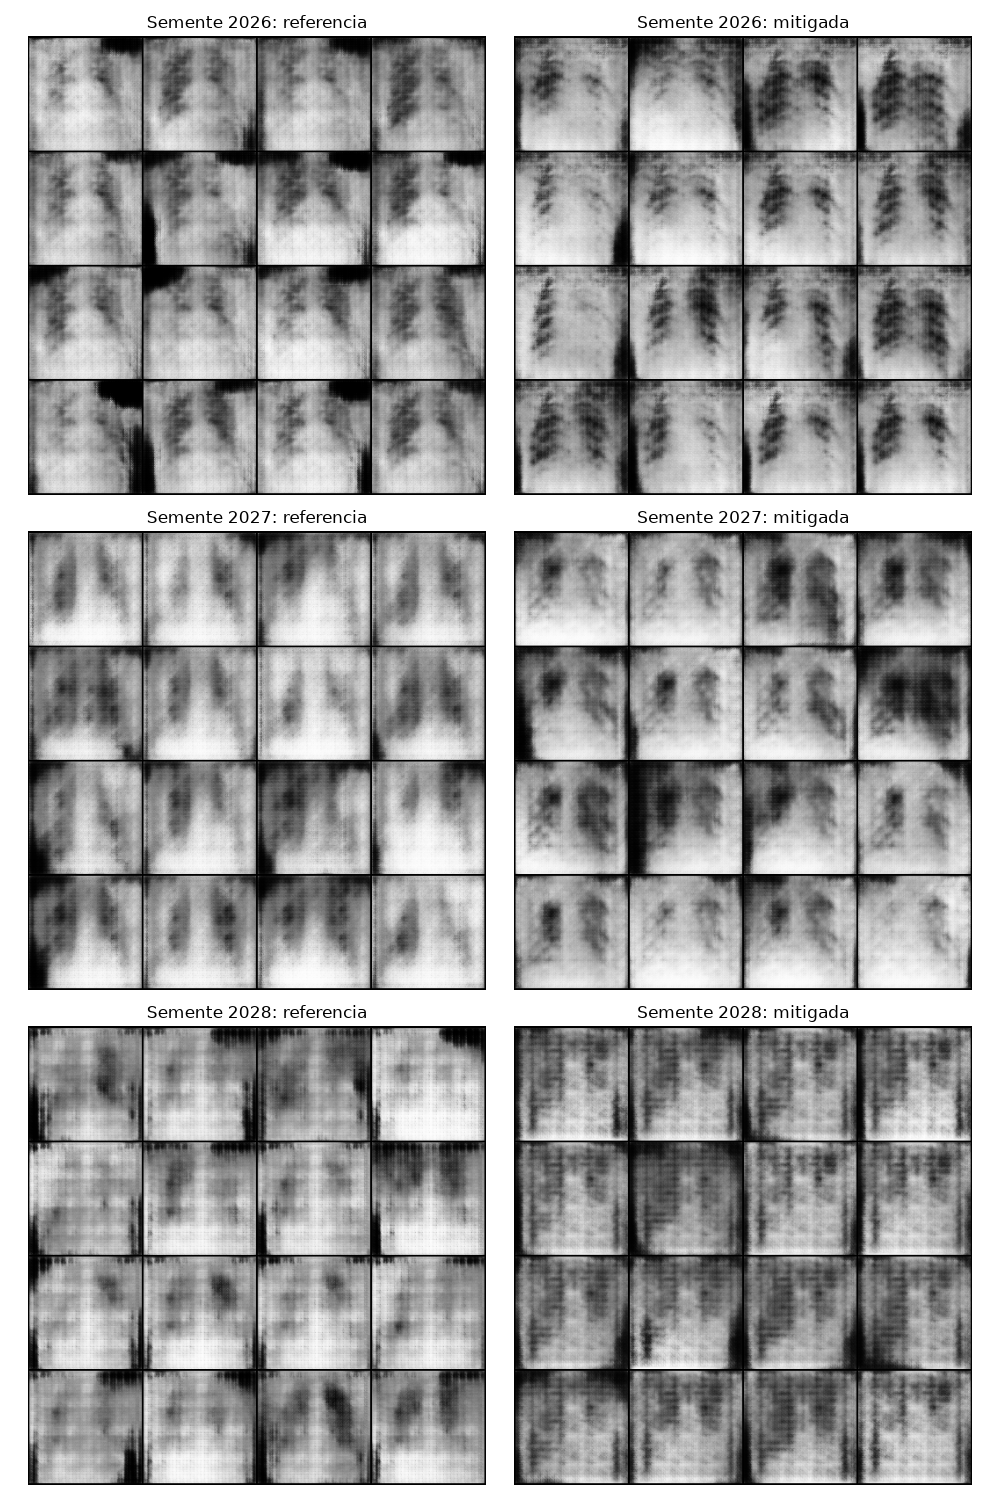

In [12]:
imagens_reais_referencia = IMAGENS_GAN[ROTULOS_GAN == INDICE_COVID][:64]
assert len(imagens_reais_referencia) == 64
miniaturas_reais = torch.nn.functional.interpolate(imagens_reais_referencia, size=(32, 32), mode='bilinear').flatten(1)
valores_reais = torch.linalg.svdvals(miniaturas_reais - miniaturas_reais.mean(0, keepdim=True))
probabilidades_reais = valores_reais.square() / valores_reais.square().sum()
posto_efetivo_real = torch.exp(-(probabilidades_reais * probabilidades_reais.clamp_min(1e-12).log()).sum()).item()
print(f'Posto efetivo das 64 imagens reais de treino: {posto_efetivo_real:.4f}')
salvar_registro(RESULTADOS / 'ablacao/referencia_real.txt', {
    'imagens': 64, 'particao': 'train', 'classe': 'COVID-19', 'posto_efetivo': posto_efetivo_real,
    'finalidade': 'Referencia exploratoria de diversidade; nao mede modos clinicos.'})
figura, eixos = plt.subplots(3, 2, figsize=(10, 15))
for linha, semente in enumerate([2026, 2027, 2028]):
    for coluna, configuracao in enumerate(['referencia', 'mitigada']):
        caminho_grade = RESULTADOS / 'ablacao' / f'{semente}_{configuracao}' / f'epoca_{CONFIGURACAO["epocas_gan"]:03d}.png'
        with Image.open(caminho_grade) as imagem_grade:
            eixos[linha, coluna].imshow(imagem_grade)
        eixos[linha, coluna].set_title(f'Semente {semente}: {configuracao}')
        eixos[linha, coluna].axis('off')
figura.tight_layout()
figura.savefig(RESULTADOS / 'ablacao/grades_pareadas.png', dpi=100)
plt.show()
